# Proyek Akhir: Menyelesaikan Permasalahan Institusi Pendidikan (Jaya Jaya Institut)

- Nama: Adam Mukharil Bachtiar
- Email: adam@email.unikom.ac.id
- Id Dicoding: adammb86

## Business Understanding

Jaya Jaya Institut sudah berdiri sejak tahun 2000 dan menghasilkan banyak lulusan dengan reputasi baik. Masalahnya, cukup banyak mahasiswa yang tidak menyelesaikan studinya (dropout). Angka dropout yang tinggi merugikan institusi dari sisi reputasi, akreditasi, dan pendapatan, sekaligus merugikan mahasiswa itu sendiri.

Pertanyaan bisnis yang ingin dijawab:
1. Berapa besar tingkat dropout saat ini dan bagaimana sebarannya per program studi?
2. Faktor apa saja (akademik, finansial, demografis) yang paling berkaitan dengan dropout?
3. Bisakah kita memprediksi mahasiswa yang berisiko dropout sedini mungkin agar bisa diberi bimbingan khusus?

## Persiapan

### Menyiapkan library yang dibutuhkan

In [1]:
import json
import sqlite3
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

### Menyiapkan data yang akan digunakan

Dataset diambil dari repositori [dicoding_dataset/students_performance](https://github.com/dicodingacademy/dicoding_dataset/tree/main/students_performance). Pemisah kolomnya titik koma, jadi perlu `sep=';'`.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/main/students_performance/data.csv"
LOCAL_PATH = Path("data/data.csv")

if LOCAL_PATH.exists():
    df = pd.read_csv(LOCAL_PATH, sep=";")
else:
    df = pd.read_csv(DATA_URL, sep=";")
    LOCAL_PATH.parent.mkdir(exist_ok=True)
    df.to_csv(LOCAL_PATH, sep=";", index=False)

df.head()

,Marital_status,Application_mode,Application_order,Course,Daytime_evening_attendance,Previous_qualification,Previous_qualification_grade,Nacionality,Mothers_qualification,Fathers_qualification,Mothers_occupation,Fathers_occupation,Admission_grade,Displaced,Educational_special_needs,Debtor,Tuition_fees_up_to_date,Gender,Scholarship_holder,Age_at_enrollment,International,Curricular_units_1st_sem_credited,Curricular_units_1st_sem_enrolled,Curricular_units_1st_sem_evaluations,Curricular_units_1st_sem_approved,Curricular_units_1st_sem_grade,Curricular_units_1st_sem_without_evaluations,Curricular_units_2nd_sem_credited,Curricular_units_2nd_sem_enrolled,Curricular_units_2nd_sem_evaluations,Curricular_units_2nd_sem_approved,Curricular_units_2nd_sem_grade,Curricular_units_2nd_sem_without_evaluations,Unemployment_rate,Inflation_rate,GDP,Status
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Data Understanding

In [3]:
print("Ukuran data:", df.shape)
df.info()

Ukuran data: (4424, 37)
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Marital_status                                4424 non-null   int64  
 1   Application_mode                              4424 non-null   int64  
 2   Application_order                             4424 non-null   int64  
 3   Course                                        4424 non-null   int64  
 4   Daytime_evening_attendance                    4424 non-null   int64  
 5   Previous_qualification                        4424 non-null   int64  
 6   Previous_qualification_grade                  4424 non-null   float64
 7   Nacionality                                   4424 non-null   int64  
 8   Mothers_qualification                         4424 non-null   int64  
 9   Fathers_qualification                         4424

In [4]:
print("Jumlah missing value:", df.isna().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())
df.describe().T

Jumlah missing value: 0
Jumlah baris duplikat: 0


,count,mean,std,min,25%,50%,75%,max
Marital_status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application_mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application_order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime_evening_attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous_qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous_qualification_grade,4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mothers_qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Fathers_qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


Data berisi 4.424 mahasiswa dan 37 kolom. Tidak ada missing value maupun baris duplikat. Semua fitur sudah berupa angka, termasuk fitur kategorikal yang disimpan sebagai kode (misalnya `Course`, `Application_mode`). Kolom target adalah `Status` dengan tiga nilai: Dropout, Enrolled, dan Graduate.

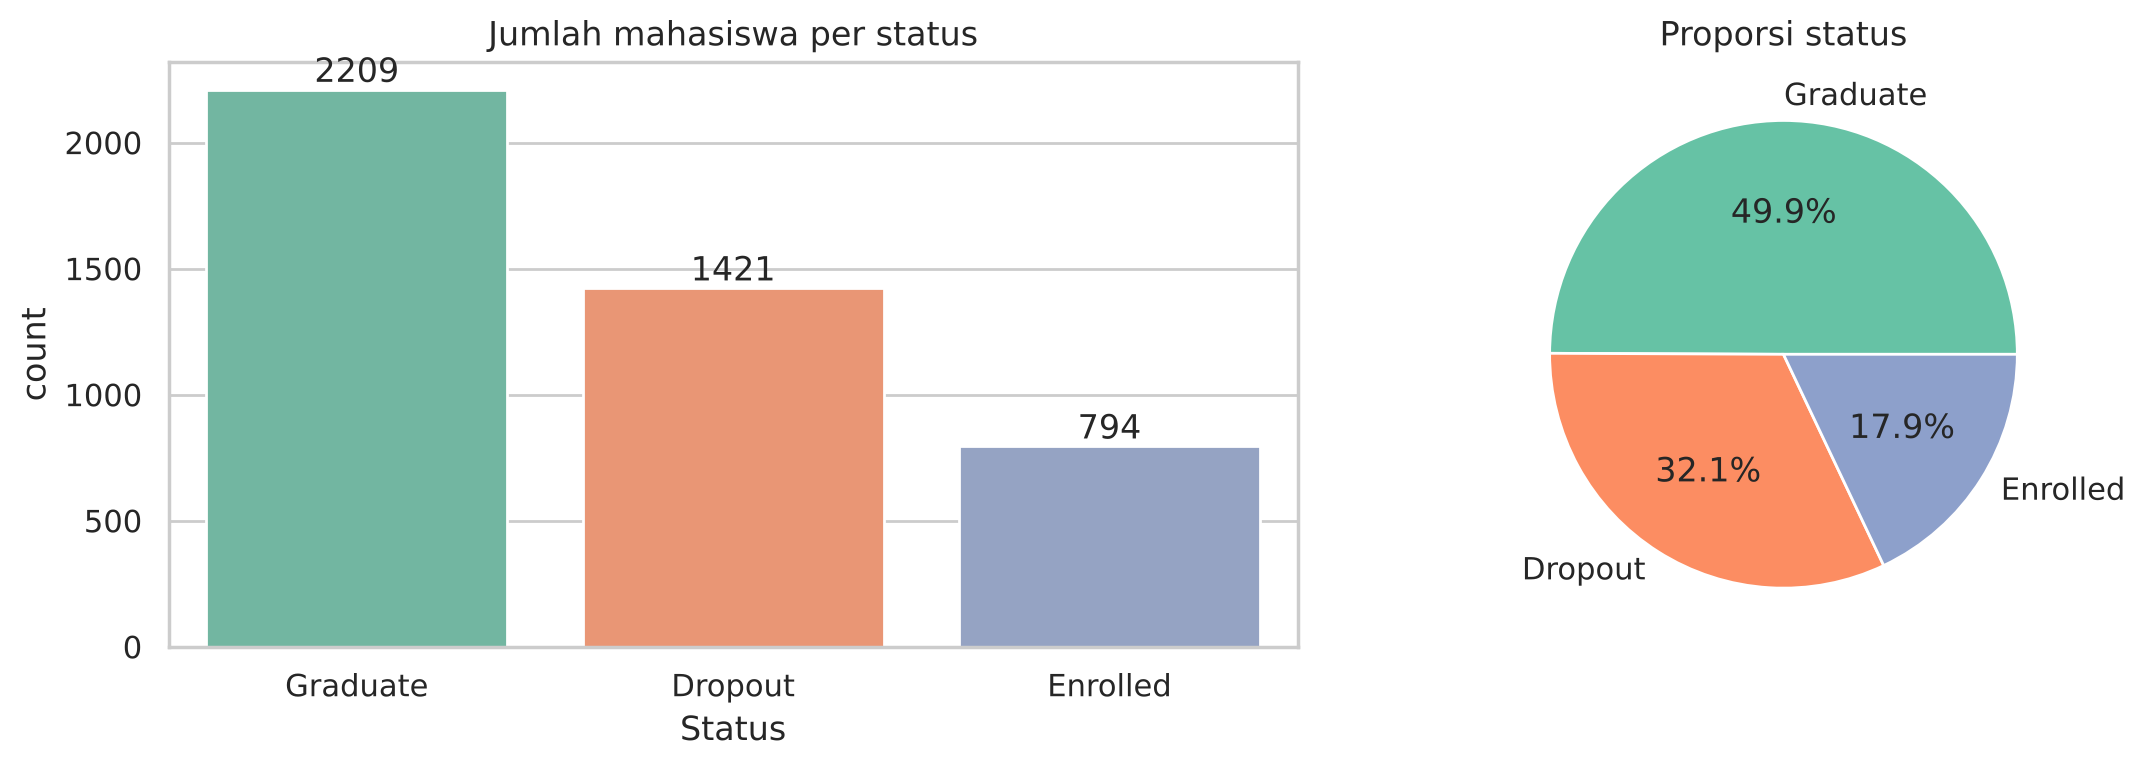

In [5]:
status_counts = df["Status"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Status", order=status_counts.index, palette="Set2", ax=ax[0])
ax[0].set_title("Jumlah mahasiswa per status")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[1].pie(status_counts, labels=status_counts.index, autopct="%.1f%%", colors=sns.color_palette("Set2"))
ax[1].set_title("Proporsi status")
plt.tight_layout(); plt.show()

Sekitar **32%** mahasiswa berstatus Dropout, 50% Graduate, dan 18% masih Enrolled. Artinya hampir satu dari tiga mahasiswa tidak menyelesaikan studinya.

### Memberi label yang mudah dibaca

Beberapa kolom kategorikal masih berupa kode. Supaya analisis dan dashboard lebih mudah dipahami, kode tersebut dipetakan ke label sesuai dokumentasi dataset.

In [6]:
COURSE_MAP = {33: "Biofuel Production Technologies", 171: "Animation and Multimedia Design",
              8014: "Social Service (evening)", 9003: "Agronomy", 9070: "Communication Design",
              9085: "Veterinary Nursing", 9119: "Informatics Engineering", 9130: "Equinculture",
              9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
              9556: "Oral Hygiene", 9670: "Advertising and Marketing Management",
              9773: "Journalism and Communication", 9853: "Basic Education",
              9991: "Management (evening)"}
MARITAL_MAP = {1: "Single", 2: "Married", 3: "Widower", 4: "Divorced", 5: "Facto union", 6: "Legally separated"}
APP_MODE_MAP = {1: "1st phase - general contingent", 2: "Ordinance No. 612/93",
                5: "1st phase - special contingent (Azores)", 7: "Holders of other higher courses",
                10: "Ordinance No. 854-B/99", 15: "International student (bachelor)",
                16: "1st phase - special contingent (Madeira)", 17: "2nd phase - general contingent",
                18: "3rd phase - general contingent", 26: "Ordinance No. 533-A/99 b2",
                27: "Ordinance No. 533-A/99 b3", 39: "Over 23 years old", 42: "Transfer",
                43: "Change of course", 44: "Technological specialization diploma",
                51: "Change of institution/course", 53: "Short cycle diploma holders",
                57: "Change of institution/course (International)"}

labeled = df.copy()
labeled["Course_name"] = labeled["Course"].map(COURSE_MAP)
labeled["Marital_status_name"] = labeled["Marital_status"].map(MARITAL_MAP)
labeled["Application_mode_name"] = labeled["Application_mode"].map(APP_MODE_MAP)
labeled["Gender_name"] = labeled["Gender"].map({1: "Male", 0: "Female"})
labeled["Is_dropout"] = (labeled["Status"] == "Dropout").astype(int)
labeled["Age_group"] = pd.cut(labeled["Age_at_enrollment"], bins=[0, 20, 24, 30, 100],
                              labels=["<=20", "21-24", "25-30", ">30"])
labeled[["Course", "Course_name", "Application_mode_name", "Gender_name", "Status"]].head()

,Course,Course_name,Application_mode_name,Gender_name,Status
0,171,Animation and Multimedia Design,2nd phase - general contingent,Male,Dropout
1,9254,Tourism,International student (bachelor),Male,Graduate
2,9070,Communication Design,1st phase - general contingent,Male,Dropout
3,9773,Journalism and Communication,2nd phase - general contingent,Female,Graduate
4,8014,Social Service (evening),Over 23 years old,Female,Graduate


### Dropout per program studi

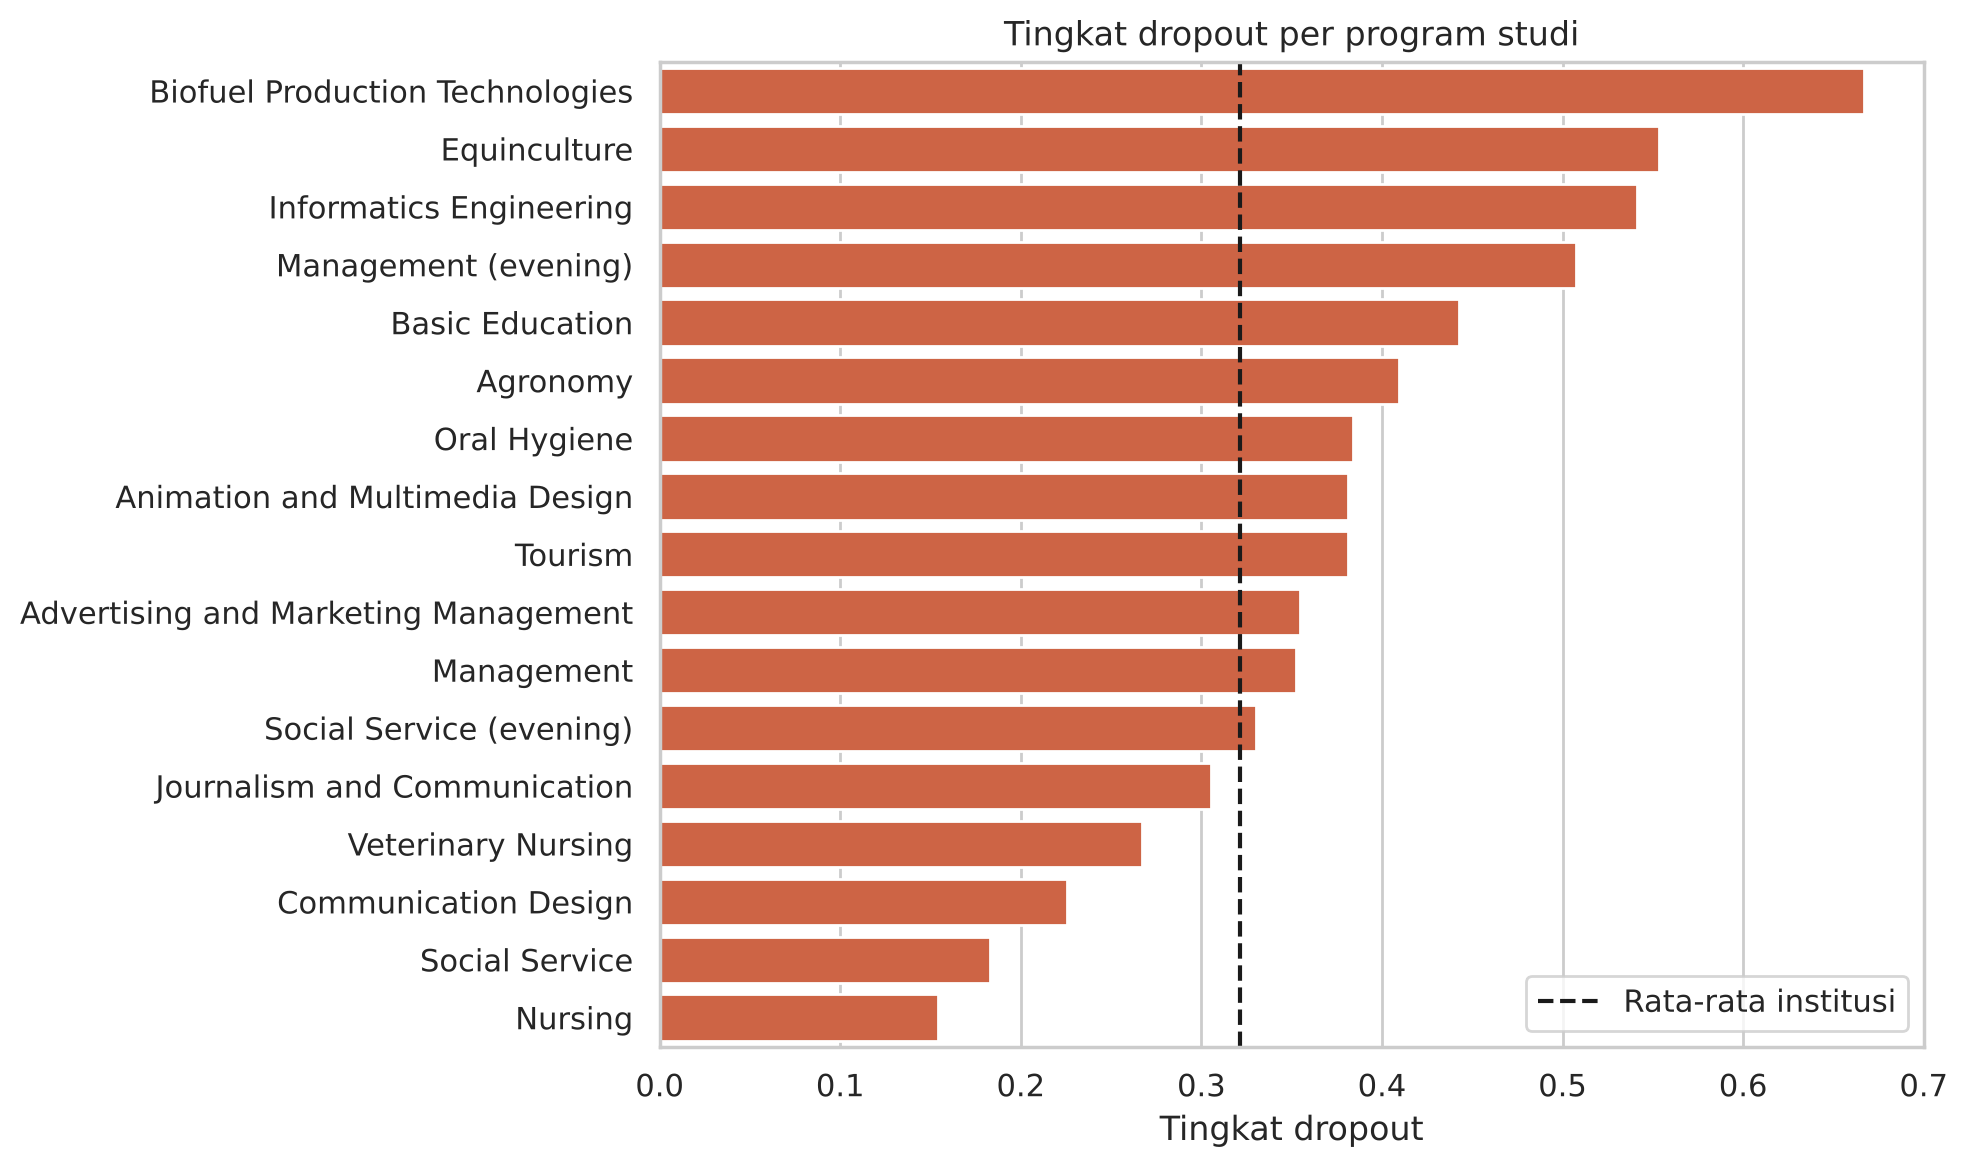

,students,dropout_rate
Course_name,,
Biofuel Production Technologies,12,66.7%
Equinculture,141,55.3%
Informatics Engineering,170,54.1%
Management (evening),268,50.7%
Basic Education,192,44.3%
Agronomy,210,41.0%
Oral Hygiene,86,38.4%
Animation and Multimedia Design,215,38.1%
Tourism,252,38.1%


In [7]:
course_rate = (labeled.groupby("Course_name")
               .agg(students=("Is_dropout", "size"), dropout_rate=("Is_dropout", "mean"))
               .sort_values("dropout_rate", ascending=False))
plt.figure(figsize=(10, 6))
sns.barplot(data=course_rate.reset_index(), y="Course_name", x="dropout_rate", color="#e4572e")
plt.axvline(labeled["Is_dropout"].mean(), ls="--", c="k", label="Rata-rata institusi")
plt.title("Tingkat dropout per program studi"); plt.xlabel("Tingkat dropout"); plt.ylabel("")
plt.legend(); plt.tight_layout(); plt.show()
course_rate.style.format({"dropout_rate": "{:.1%}"})

Tingkat dropout tertinggi ada di Biofuel Production Technologies (namun hanya 12 mahasiswa), Equinculture, Informatics Engineering, dan Management (evening). Nursing dan Social Service punya tingkat dropout paling rendah.

### Faktor finansial dan demografis

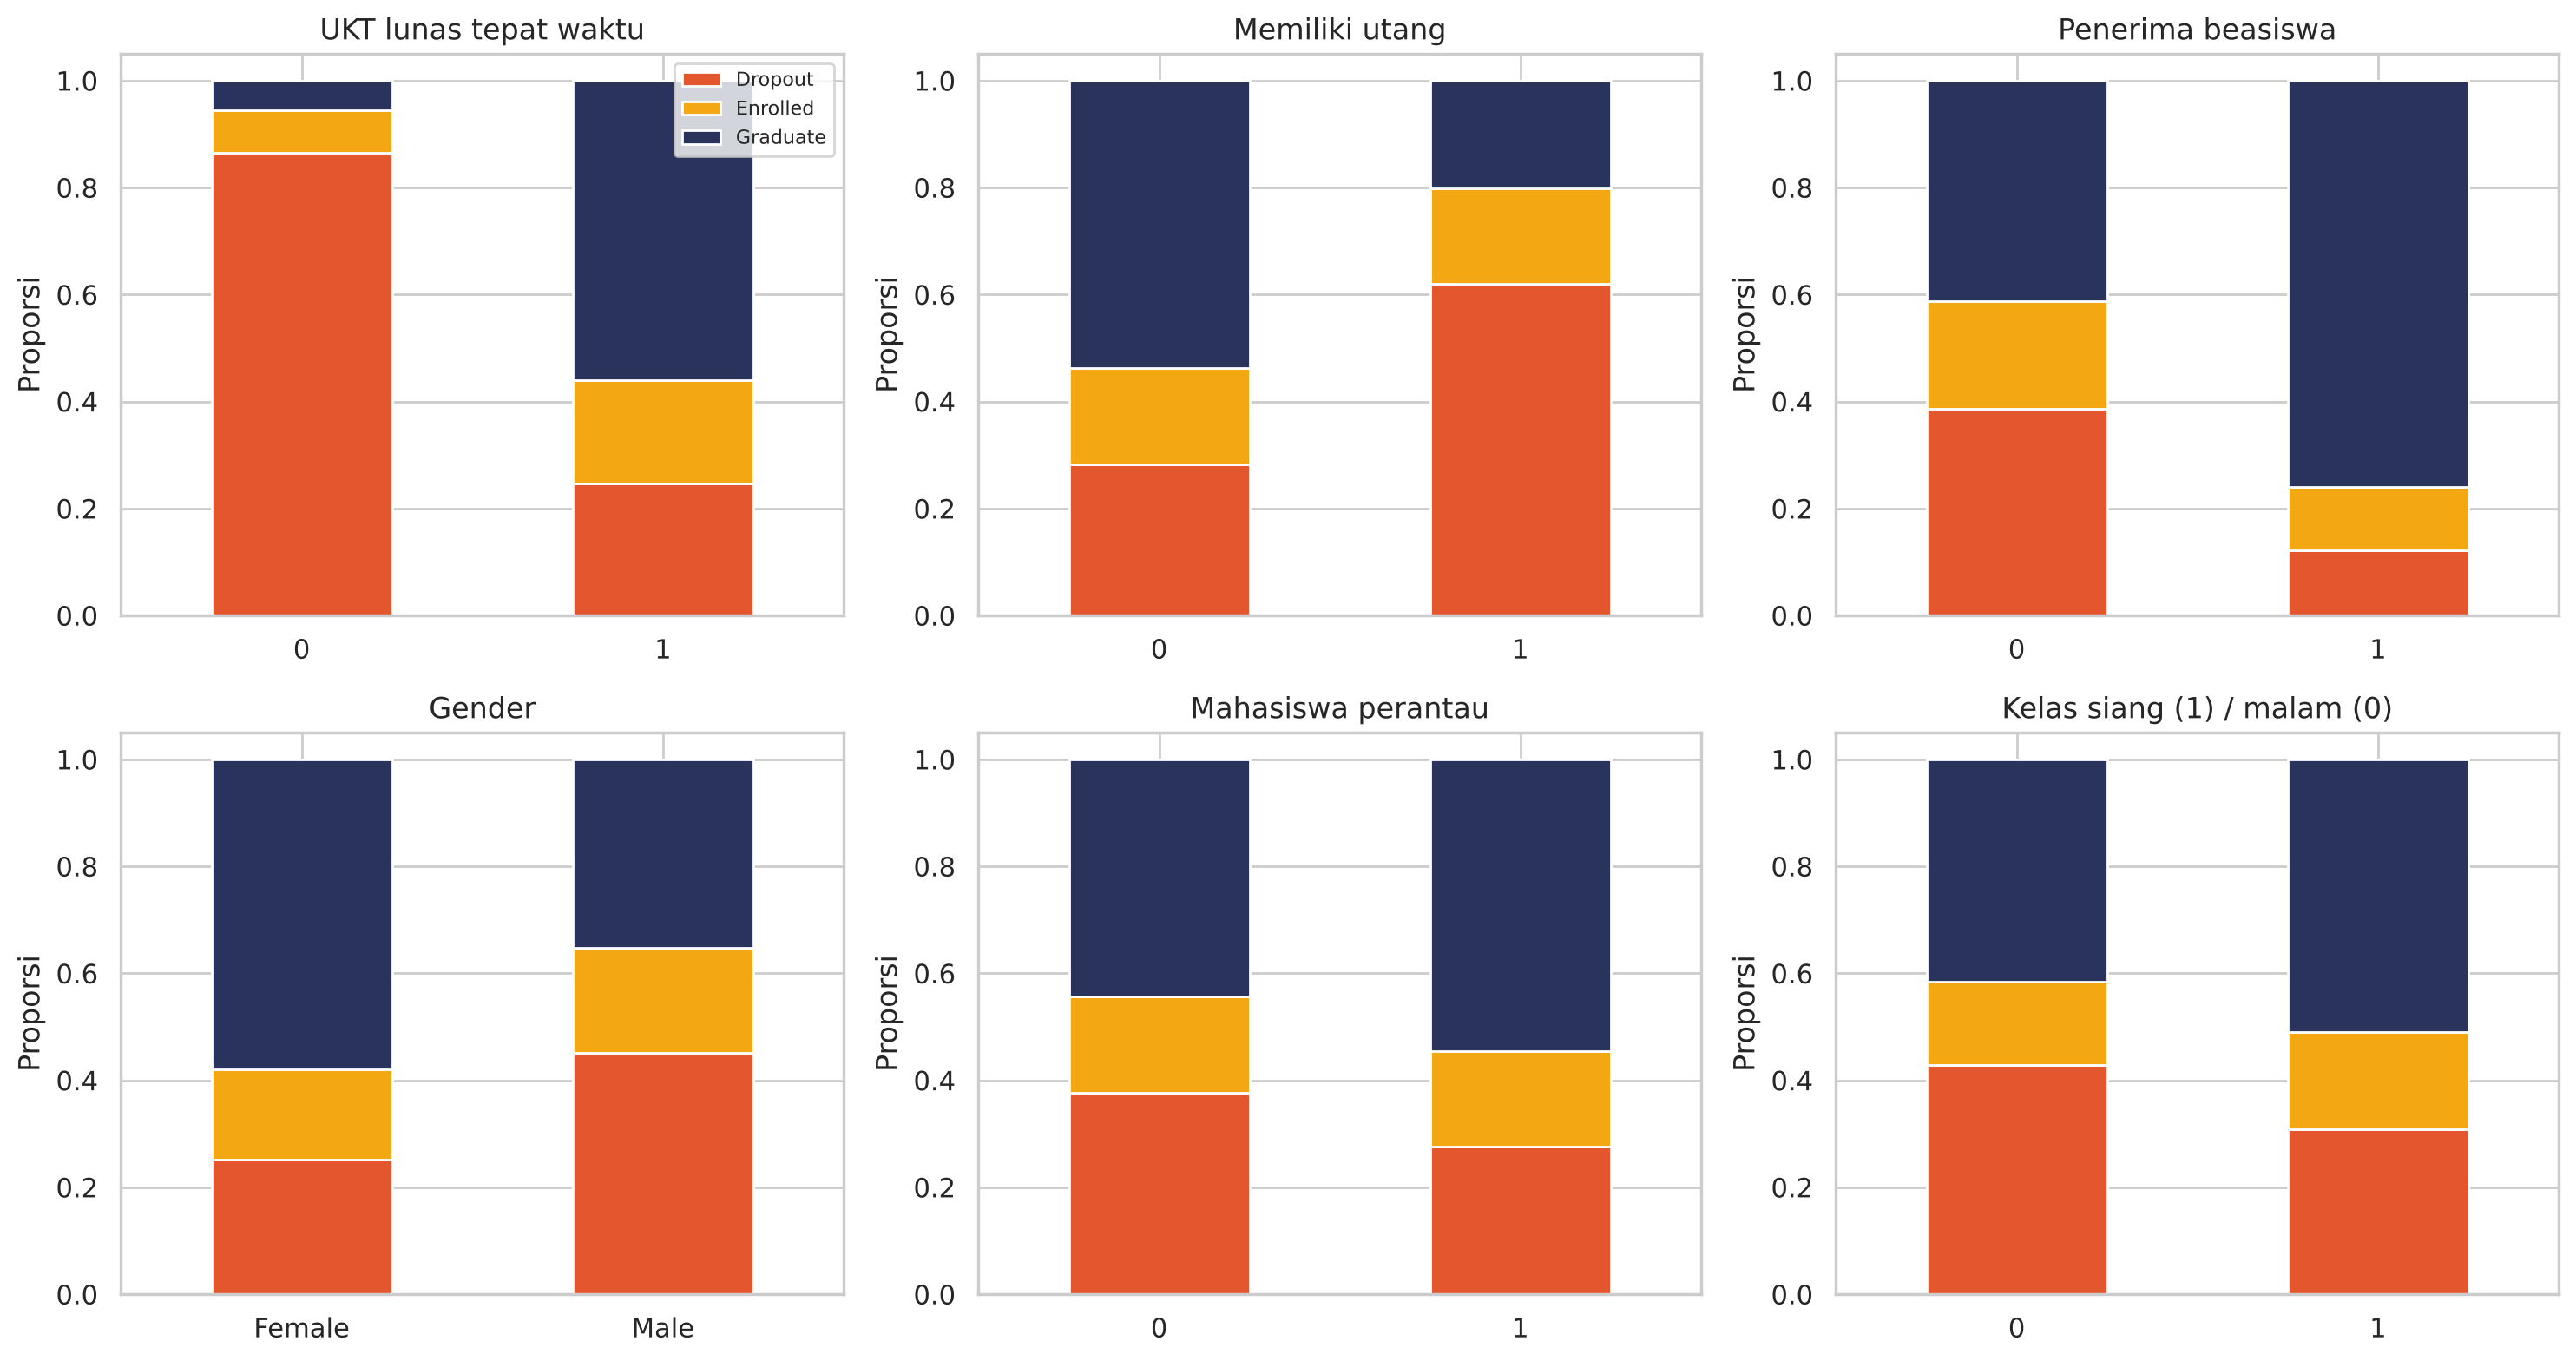

In [8]:
binary_cols = {"Tuition_fees_up_to_date": "UKT lunas tepat waktu", "Debtor": "Memiliki utang",
               "Scholarship_holder": "Penerima beasiswa", "Gender_name": "Gender",
               "Displaced": "Mahasiswa perantau", "Daytime_evening_attendance": "Kelas siang (1) / malam (0)"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.flat, binary_cols.items()):
    ct = pd.crosstab(labeled[col], labeled["Status"], normalize="index")[["Dropout", "Enrolled", "Graduate"]]
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#e4572e", "#f3a712", "#29335c"], legend=False)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Proporsi"); ax.tick_params(axis="x", rotation=0)
axes.flat[0].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

In [9]:
for col in ["Tuition_fees_up_to_date", "Debtor", "Scholarship_holder", "Gender_name", "Age_group"]:
    print(labeled.groupby(col, observed=True)["Is_dropout"].mean().round(3).to_dict(), "<-", col)

{0: 0.866, 1: 0.247} <- Tuition_fees_up_to_date
{0: 0.283, 1: 0.62} <- Debtor
{0: 0.387, 1: 0.122} <- Scholarship_holder
{'Female': 0.251, 'Male': 0.451} <- Gender_name
{'<=20': 0.212, '21-24': 0.337, '25-30': 0.58, '>30': 0.536} <- Age_group


Insight utama dari faktor non-akademik:
- Mahasiswa yang **UKT-nya tidak lunas tepat waktu** punya tingkat dropout sekitar **87%**, dibanding 25% pada yang lunas. Ini sinyal finansial paling kuat.
- Mahasiswa **yang memiliki utang** dropout 62%, hampir dua kali lipat mahasiswa tanpa utang (28%).
- **Penerima beasiswa** jauh lebih jarang dropout (12% vs 39%).
- Mahasiswa laki-laki lebih banyak dropout (45%) daripada perempuan (25%).
- Semakin tua usia saat masuk, semakin tinggi risiko dropout. Kelompok usia 25 tahun ke atas dropout lebih dari 50%.

### Faktor akademik semester 1 dan 2

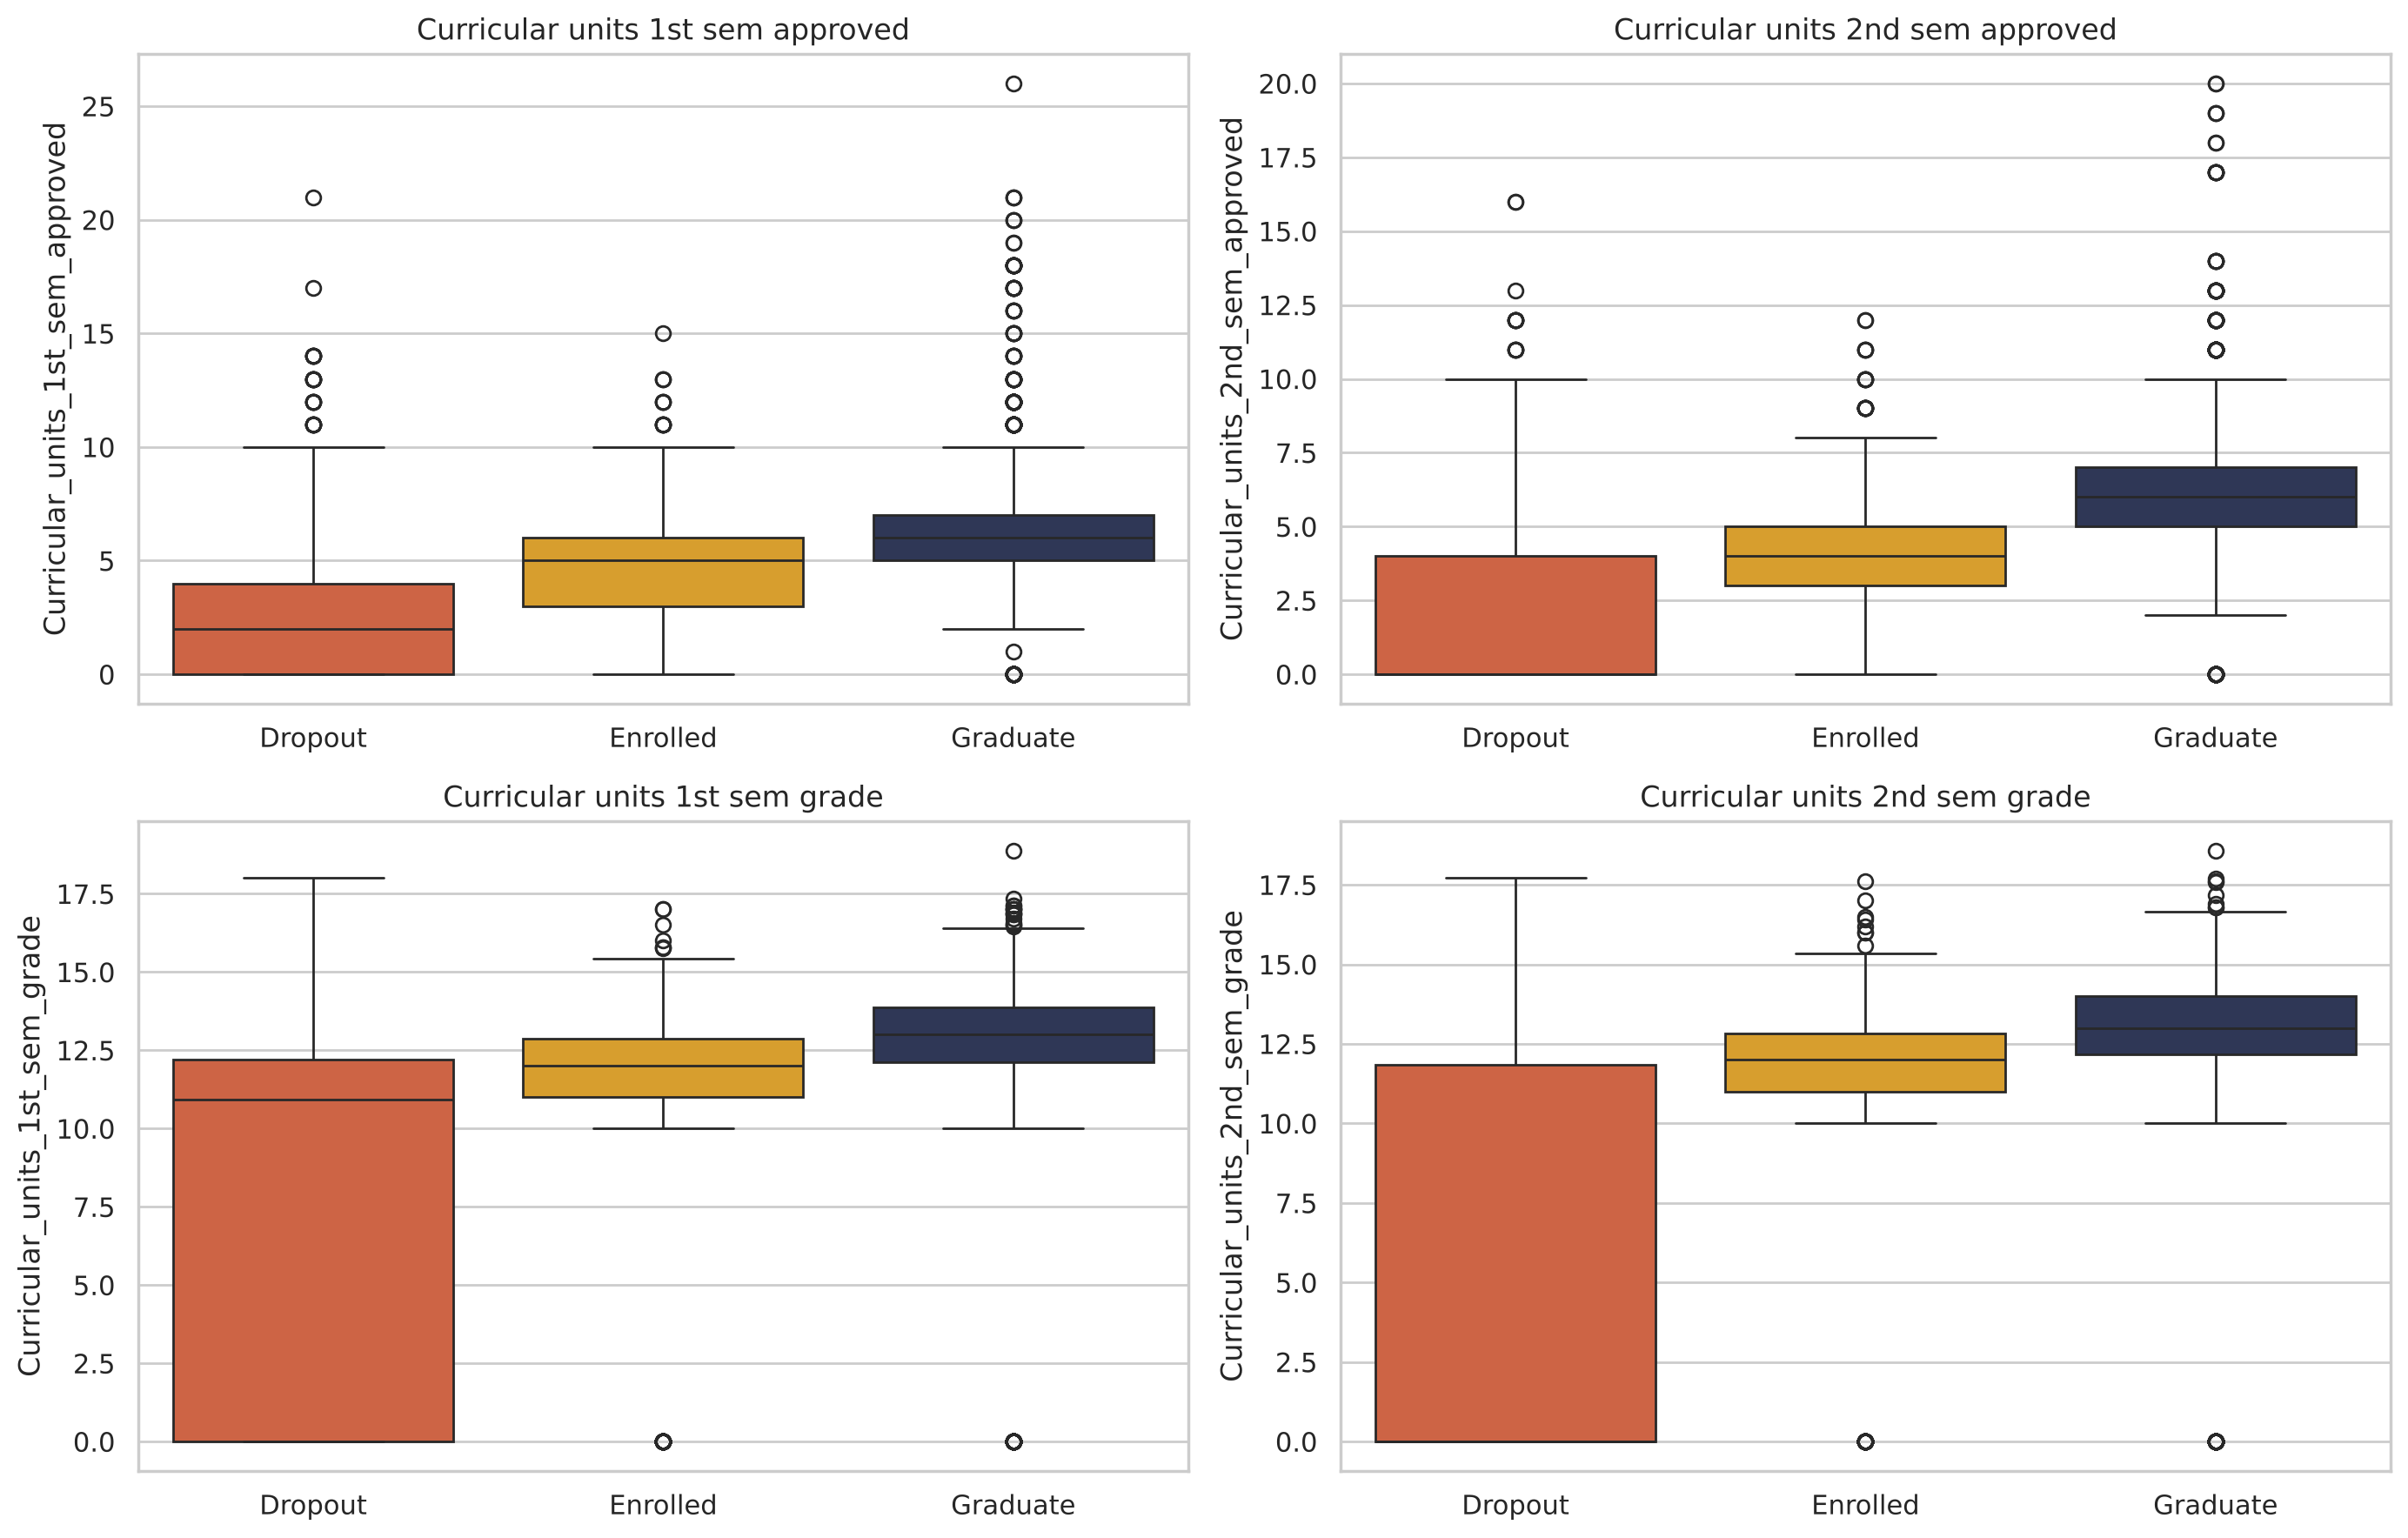

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
cols = ["Curricular_units_1st_sem_approved", "Curricular_units_2nd_sem_approved",
        "Curricular_units_1st_sem_grade", "Curricular_units_2nd_sem_grade"]
for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=labeled, x="Status", y=col, order=["Dropout", "Enrolled", "Graduate"],
                palette=["#e4572e", "#f3a712", "#29335c"], ax=ax)
    ax.set_title(col.replace("_", " ")); ax.set_xlabel("")
plt.tight_layout(); plt.show()

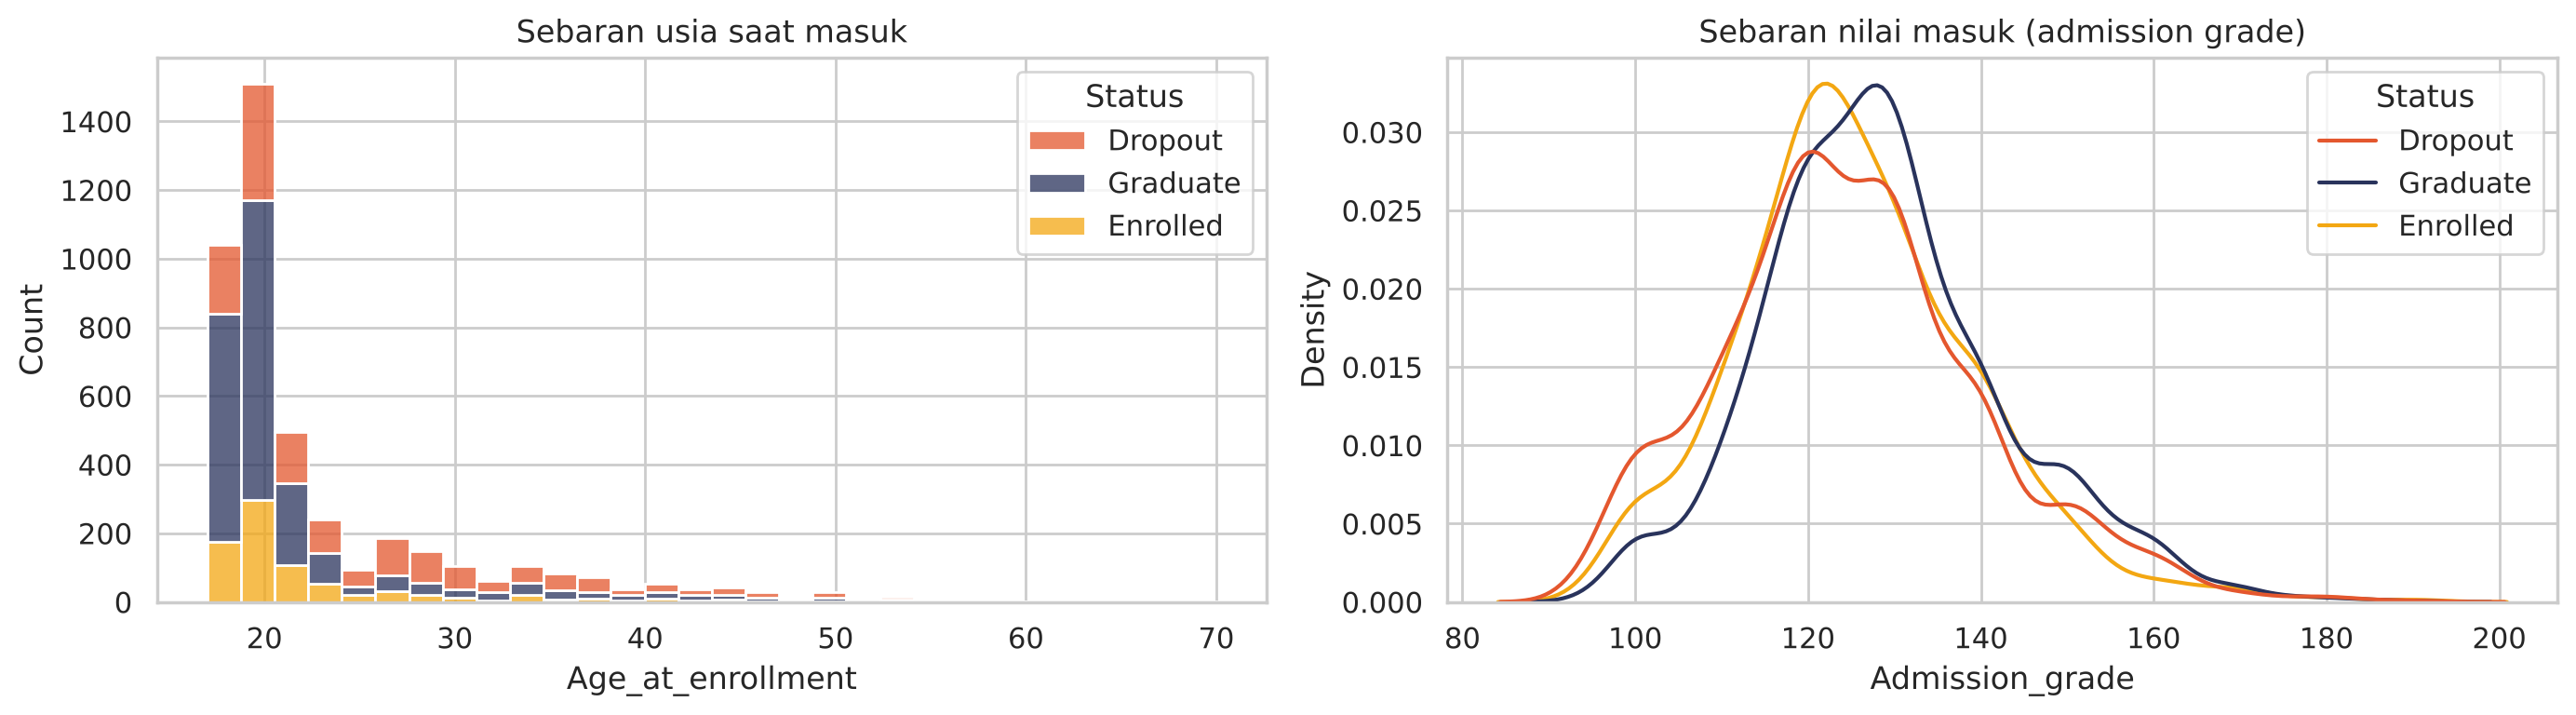

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=labeled, x="Age_at_enrollment", hue="Status", multiple="stack", bins=30,
             palette={"Dropout": "#e4572e", "Enrolled": "#f3a712", "Graduate": "#29335c"}, ax=ax[0])
ax[0].set_title("Sebaran usia saat masuk")
sns.kdeplot(data=labeled, x="Admission_grade", hue="Status", common_norm=False,
            palette={"Dropout": "#e4572e", "Enrolled": "#f3a712", "Graduate": "#29335c"}, ax=ax[1])
ax[1].set_title("Sebaran nilai masuk (admission grade)")
plt.tight_layout(); plt.show()

Performa akademik di tahun pertama adalah pembeda paling jelas. Mahasiswa dropout umumnya hanya meluluskan sedikit unit kurikuler (median mendekati 0 sampai 3) dan nilainya rendah, bahkan banyak yang bernilai 0 karena tidak mengikuti evaluasi. Mahasiswa Graduate rata-rata lulus 5 sampai 6 unit per semester dengan nilai sekitar 12 sampai 14. Nilai masuk (admission grade) juga sedikit lebih rendah pada kelompok dropout, tetapi perbedaannya tidak sebesar faktor akademik semester berjalan.

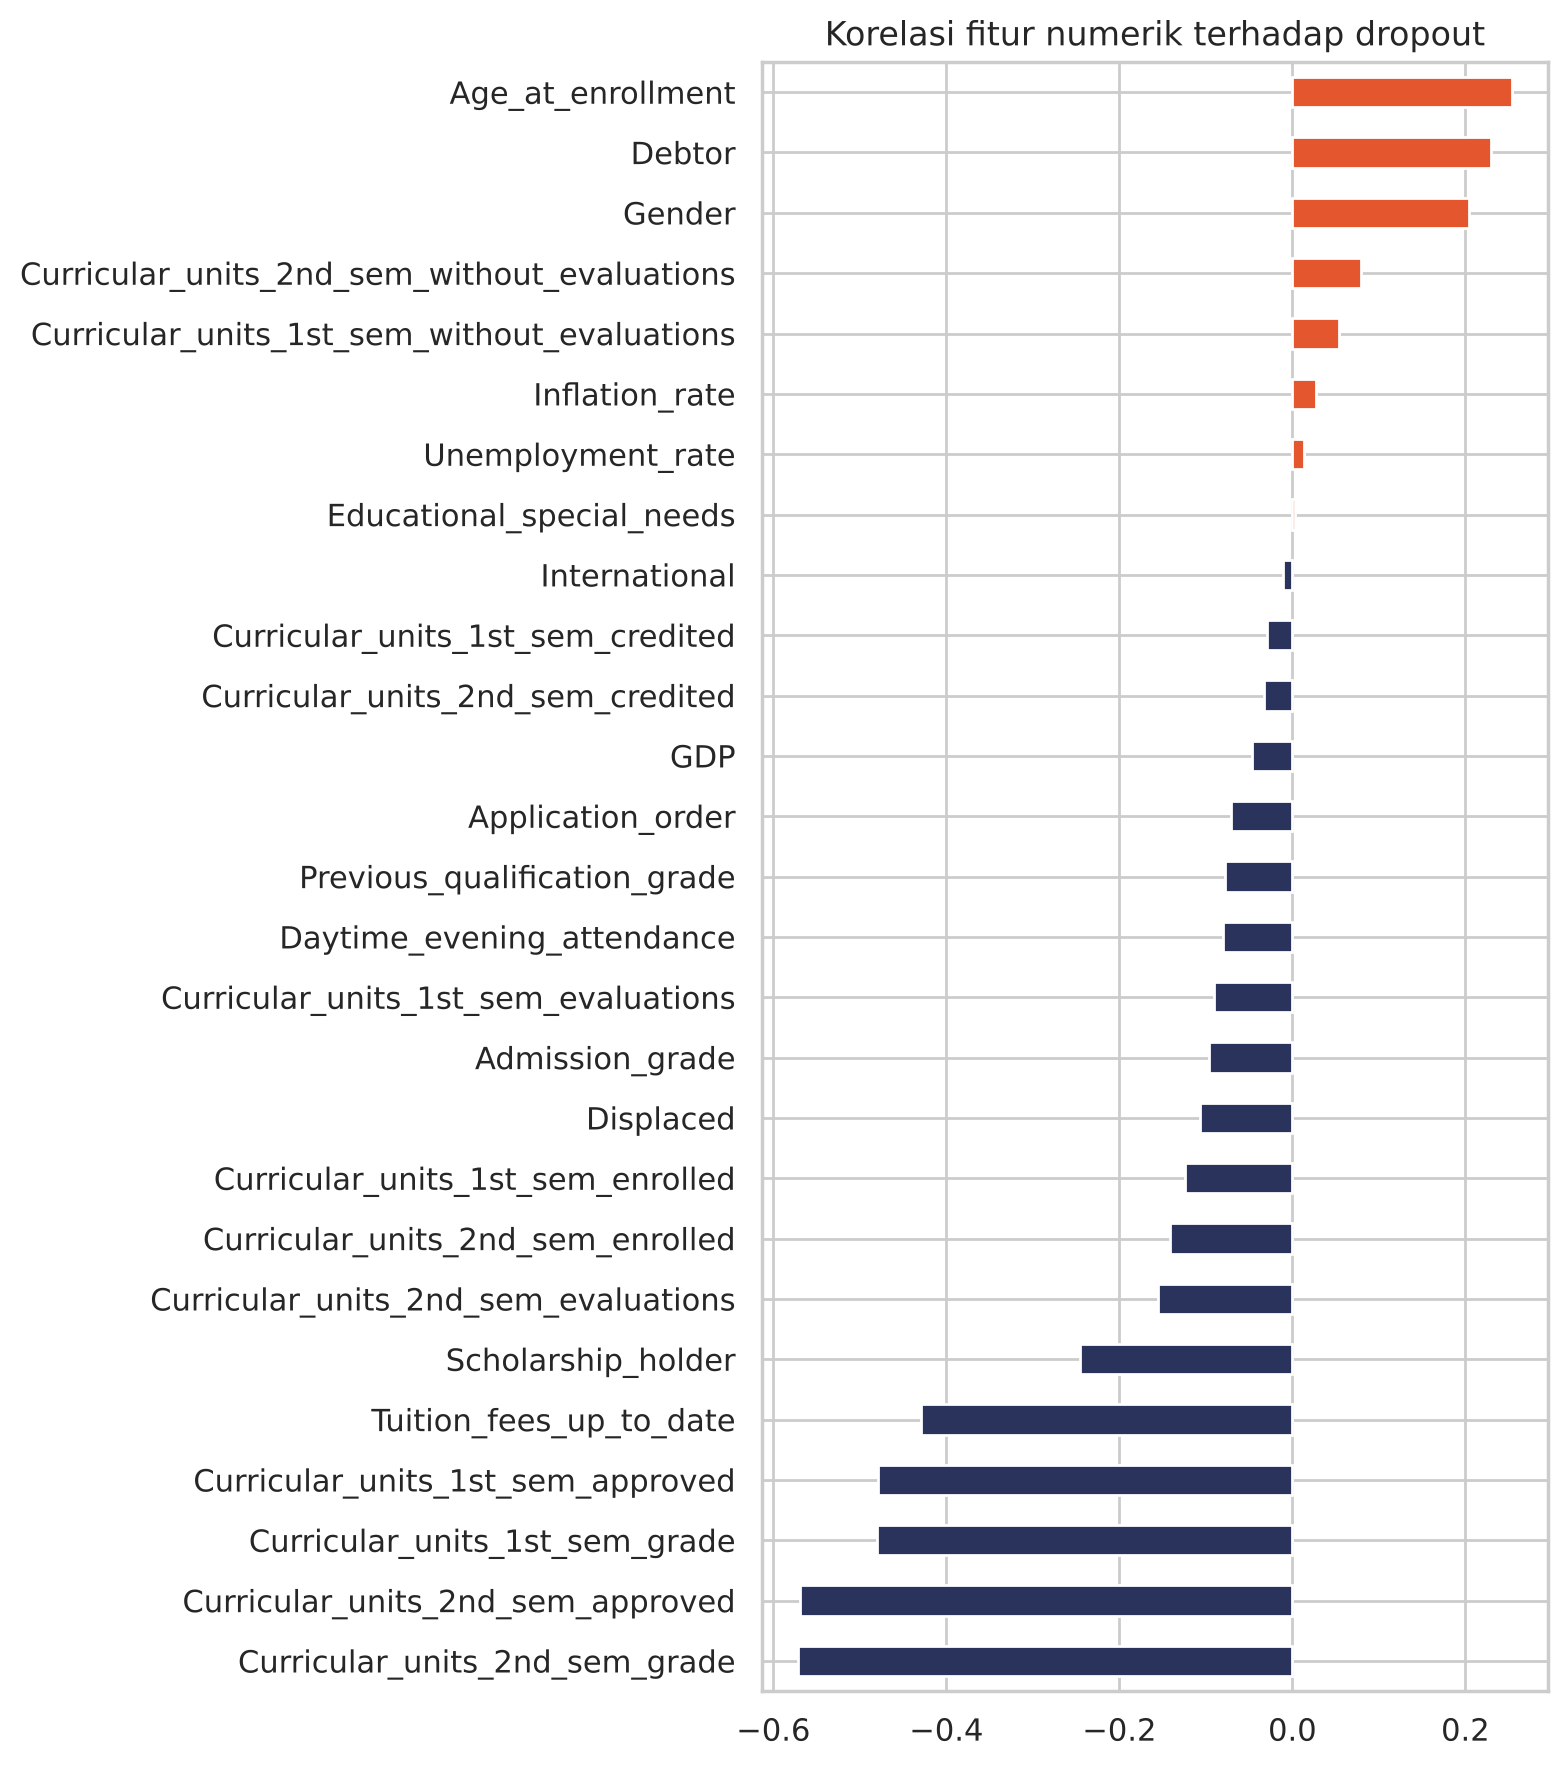

In [12]:
num = labeled.select_dtypes("number").drop(columns=["Course", "Application_mode", "Marital_status", "Nacionality",
                                                     "Mothers_occupation", "Fathers_occupation",
                                                     "Mothers_qualification", "Fathers_qualification",
                                                     "Previous_qualification"])
corr = num.corr()["Is_dropout"].drop("Is_dropout").sort_values()
plt.figure(figsize=(8, 9))
corr.plot(kind="barh", color=np.where(corr > 0, "#e4572e", "#29335c"))
plt.title("Korelasi fitur numerik terhadap dropout"); plt.tight_layout(); plt.show()

Korelasi negatif terkuat ada pada jumlah unit yang lulus dan nilai di semester 1 dan 2, lalu status UKT dan beasiswa. Korelasi positif terkuat ada pada usia saat masuk, status debitur, dan gender laki-laki. Indikator makroekonomi (pengangguran, inflasi, GDP) hampir tidak berkorelasi dengan dropout.

## Data Preparation / Preprocessing

Keputusan persiapan data:
1. **Target biner.** Fokus bisnis adalah mendeteksi dropout, jadi target dibuat biner: 1 = Dropout, 0 = Graduate.
2. **Mahasiswa Enrolled dipisahkan.** Status akhir mereka belum diketahui sehingga tidak dipakai untuk melatih model. Justru kelompok inilah yang nanti diprediksi risikonya, karena mereka yang masih bisa diselamatkan.
3. **Seleksi fitur.** Dipilih 17 fitur yang paling relevan (berdasarkan EDA dan feature importance) dan masuk akal untuk diisi petugas akademik di aplikasi. Pada bagian Modeling, performa model dengan 17 fitur ini dibandingkan dengan model yang memakai semua 36 fitur.
4. **Split data** 80:20 secara stratified agar proporsi kelas terjaga.

In [13]:
FEATURES = [
    "Curricular_units_1st_sem_enrolled", "Curricular_units_1st_sem_evaluations",
    "Curricular_units_1st_sem_approved", "Curricular_units_1st_sem_grade",
    "Curricular_units_2nd_sem_enrolled", "Curricular_units_2nd_sem_evaluations",
    "Curricular_units_2nd_sem_approved", "Curricular_units_2nd_sem_grade",
    "Tuition_fees_up_to_date", "Debtor", "Scholarship_holder",
    "Age_at_enrollment", "Gender", "Admission_grade", "Previous_qualification_grade",
    "Course", "Application_mode",
]
ALL_FEATURES = [c for c in df.columns if c != "Status"]

train_df = df[df["Status"] != "Enrolled"].copy()
enrolled_df = df[df["Status"] == "Enrolled"].copy()
y = (train_df["Status"] == "Dropout").astype(int)

X_train_all, X_test_all, y_train, y_test = train_test_split(
    train_df[ALL_FEATURES], y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_test = X_train_all[FEATURES], X_test_all[FEATURES]

print("Data latih :", X_train.shape, "| proporsi dropout:", round(y_train.mean(), 3))
print("Data uji   :", X_test.shape, "| proporsi dropout:", round(y_test.mean(), 3))
print("Mahasiswa Enrolled (untuk diprediksi):", enrolled_df.shape[0])

Data latih : (2904, 17) | proporsi dropout: 0.392
Data uji   : (726, 17) | proporsi dropout: 0.391
Mahasiswa Enrolled (untuk diprediksi): 794


Proporsi Dropout di data latih sekitar 39%. Kelasnya tidak terlalu timpang, tetapi tetap dipakai `class_weight='balanced'` pada model yang mendukungnya agar recall kelas Dropout terjaga.

## Modeling

Tiga algoritma dibandingkan dengan 5-fold stratified cross validation memakai metrik F1 untuk kelas Dropout.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = []
for name, model in candidates.items():
    for fset_name, Xtr in [("17 fitur terpilih", X_train), ("Semua 36 fitur", X_train_all)]:
        f1 = cross_val_score(model, Xtr, y_train, cv=cv, scoring="f1")
        auc = cross_val_score(model, Xtr, y_train, cv=cv, scoring="roc_auc")
        rows.append({"model": name, "fitur": fset_name, "cv_f1": f1.mean(), "cv_roc_auc": auc.mean()})
cv_result = pd.DataFrame(rows).sort_values("cv_f1", ascending=False)
cv_result.style.format({"cv_f1": "{:.3f}", "cv_roc_auc": "{:.3f}"})

,model,fitur,cv_f1,cv_roc_auc
1,Logistic Regression,Semua 36 fitur,0.870,0.947
0,Logistic Regression,17 fitur terpilih,0.870,0.942
4,Gradient Boosting,17 fitur terpilih,0.869,0.945
5,Gradient Boosting,Semua 36 fitur,0.866,0.948
3,Random Forest,Semua 36 fitur,0.863,0.947
2,Random Forest,17 fitur terpilih,0.863,0.946


Selisih performa antara 17 fitur dan 36 fitur sangat kecil, jadi model dengan 17 fitur dipilih karena lebih sederhana dan lebih praktis dipakai di aplikasi. Random Forest kemudian di-tuning dengan GridSearchCV.

In [15]:
param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", 0.5],
}
grid = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
                    param_grid, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
print("Parameter terbaik:", grid.best_params_)
print("CV F1 terbaik    :", round(grid.best_score_, 4))
best_model = grid.best_estimator_

Parameter terbaik: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 300}
CV F1 terbaik    : 0.8702


## Evaluation

In [16]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]
metrics = {"accuracy": accuracy_score(y_test, y_pred), "precision": precision_score(y_test, y_pred),
           "recall": recall_score(y_test, y_pred), "f1": f1_score(y_test, y_pred),
           "roc_auc": roc_auc_score(y_test, y_proba)}
print({k: round(v, 4) for k, v in metrics.items()})
print(classification_report(y_test, y_pred, target_names=["Graduate", "Dropout"]))

{'accuracy': 0.9174, 'precision': 0.8889, 'recall': 0.9014, 'f1': 0.8951, 'roc_auc': 0.9678}
              precision    recall  f1-score   support

    Graduate       0.94      0.93      0.93       442
     Dropout       0.89      0.90      0.90       284

    accuracy                           0.92       726
   macro avg       0.91      0.91      0.91       726
weighted avg       0.92      0.92      0.92       726



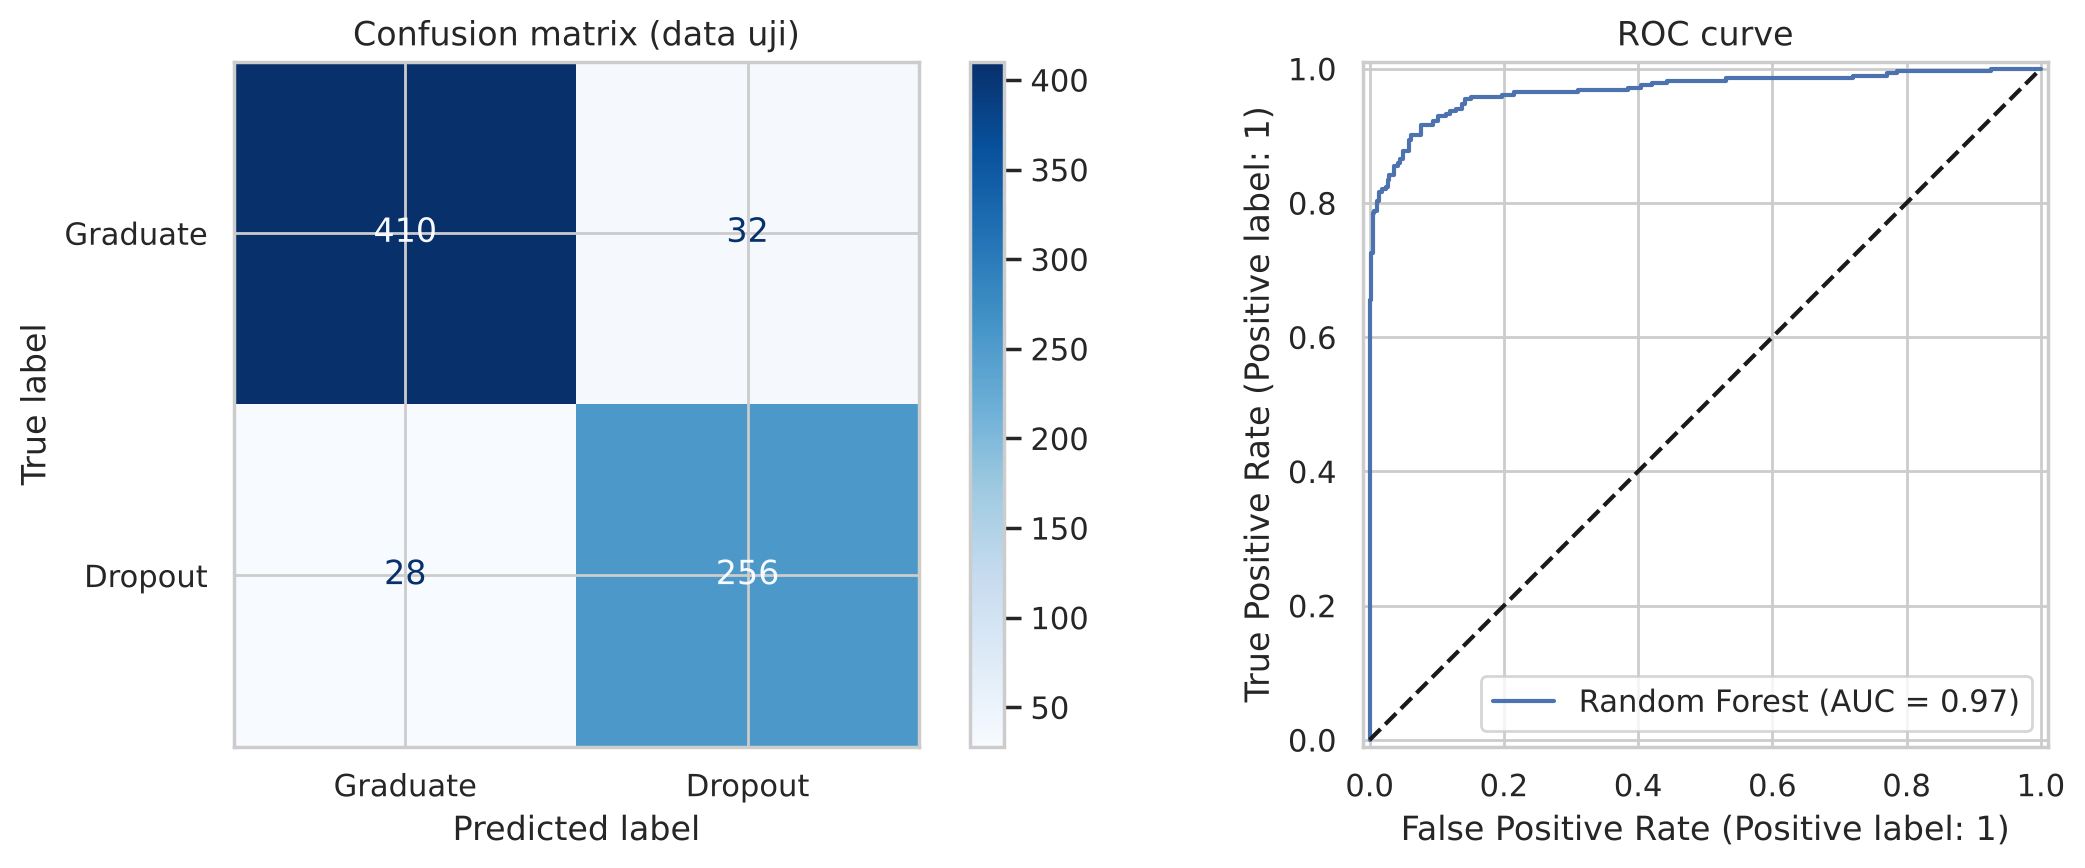

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Graduate", "Dropout"],
                                        cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion matrix (data uji)")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax[1], name="Random Forest")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC curve")
plt.tight_layout(); plt.show()

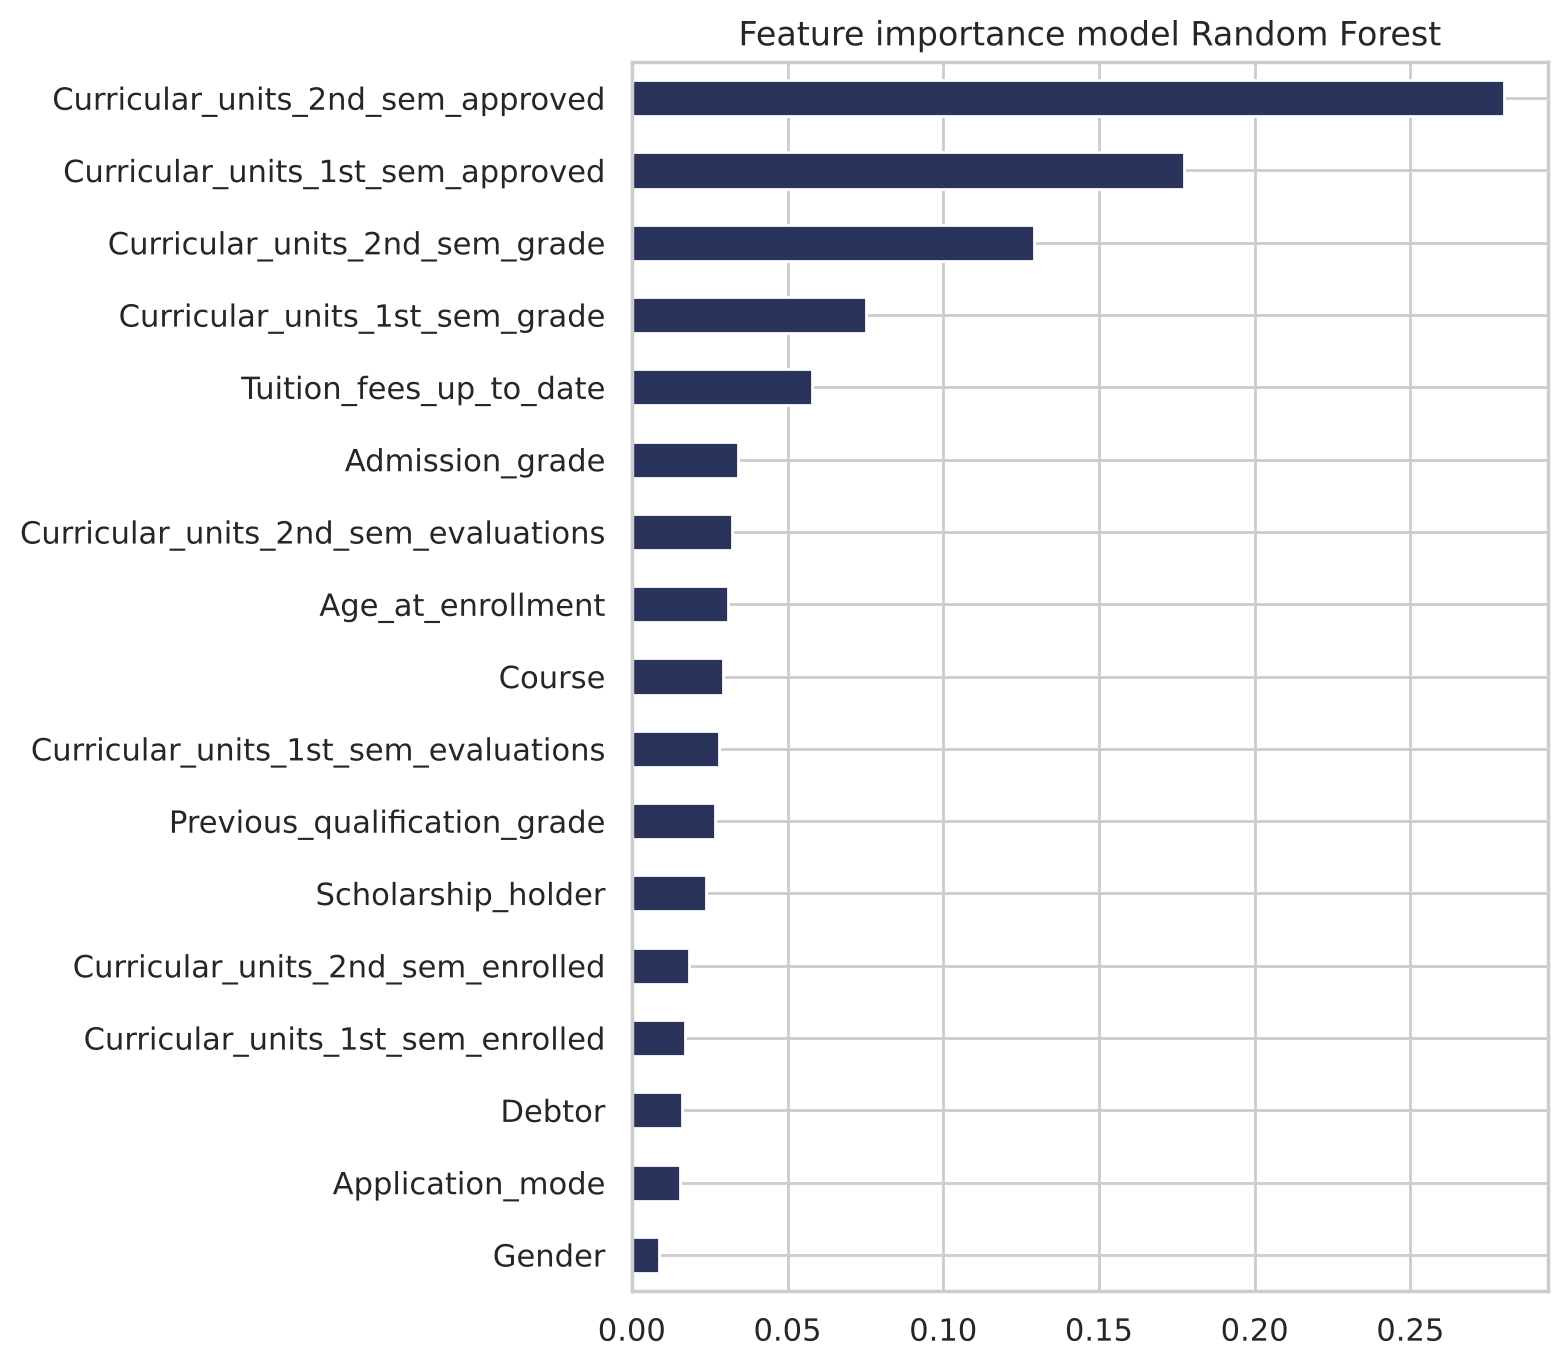

Curricular_units_2nd_sem_approved       0.280199
Curricular_units_1st_sem_approved       0.177238
Curricular_units_2nd_sem_grade          0.129034
Curricular_units_1st_sem_grade          0.075243
Tuition_fees_up_to_date                 0.057724
Admission_grade                         0.033971
Curricular_units_2nd_sem_evaluations    0.032239
Age_at_enrollment                       0.030794
Course                                  0.029367
Curricular_units_1st_sem_evaluations    0.027899
dtype: float64

In [18]:
importance = pd.Series(best_model.feature_importances_, index=FEATURES).sort_values()
plt.figure(figsize=(8, 7))
importance.plot(kind="barh", color="#29335c")
plt.title("Feature importance model Random Forest"); plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).head(10)

Model Random Forest dengan 17 fitur mencapai akurasi 91,7%, precision 0,889, recall 0,901, F1 kelas Dropout 0,895, dan ROC AUC 0,968 di data uji. Recall sekitar 90% berarti 9 dari 10 mahasiswa yang benar-benar dropout berhasil terdeteksi, dan precision 0,89 berarti peringatan yang diberikan model jarang salah sasaran. Fitur paling berpengaruh adalah jumlah unit yang lulus dan nilai semester 2 serta semester 1, diikuti status UKT, nilai masuk, dan usia saat masuk.

### Seberapa dini model bisa dipakai?

Karena tujuan institusi adalah mendeteksi **secepat mungkin**, model juga diuji hanya dengan data yang tersedia sampai akhir semester 1 (tanpa fitur semester 2). Jika performanya masih baik, intervensi bisa dimulai satu semester lebih awal.

In [19]:
early_features = [f for f in FEATURES if "2nd_sem" not in f]
early_model = RandomForestClassifier(**grid.best_params_, class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=-1).fit(X_train[early_features], y_train)
early_pred = early_model.predict(X_test[early_features])
early_proba = early_model.predict_proba(X_test[early_features])[:, 1]
pd.DataFrame({
    "Model penuh (s.d. semester 2)": [f1_score(y_test, y_pred), recall_score(y_test, y_pred), roc_auc_score(y_test, y_proba)],
    "Model dini (s.d. semester 1)": [f1_score(y_test, early_pred), recall_score(y_test, early_pred), roc_auc_score(y_test, early_proba)],
}, index=["F1", "Recall", "ROC AUC"]).round(3)

,Model penuh (s.d. semester 2),Model dini (s.d. semester 1)
F1,0.895,0.859
Recall,0.901,0.870
ROC AUC,0.968,0.945


Model dini yang hanya memakai data sampai semester 1 masih memberi F1 sekitar 0,86 dan ROC AUC sekitar 0,95, hanya sedikit di bawah model penuh. Jadi institusi bisa melakukan skrining pertama setelah nilai semester 1 keluar, lalu memperbaruinya setelah semester 2 dengan model penuh.

### Memprediksi risiko mahasiswa yang masih Enrolled

Model penuh dipakai untuk menilai 794 mahasiswa yang masih aktif (Enrolled). Mahasiswa dibagi ke tiga kategori risiko: Tinggi (probabilitas dropout >= 0,7), Sedang (0,4 sampai 0,7), dan Rendah (< 0,4).

In [20]:
def risk_level(p):
    return "Tinggi" if p >= 0.7 else ("Sedang" if p >= 0.4 else "Rendah")

enrolled_scored = enrolled_df.copy()
enrolled_scored["dropout_probability"] = best_model.predict_proba(enrolled_scored[FEATURES])[:, 1]
enrolled_scored["risk_level"] = enrolled_scored["dropout_probability"].apply(risk_level)
enrolled_scored["Course_name"] = enrolled_scored["Course"].map(COURSE_MAP)
print(enrolled_scored["risk_level"].value_counts())
(enrolled_scored[enrolled_scored["risk_level"] == "Tinggi"]
 .groupby("Course_name").size().sort_values(ascending=False).head(10)
 .rename("jumlah_mahasiswa_risiko_tinggi"))

risk_level
Rendah    313
Tinggi    292
Sedang    189
Name: count, dtype: int64


Course_name
Management                         59
Informatics Engineering            47
Veterinary Nursing                 33
Social Service                     20
Management (evening)               19
Tourism                            15
Agronomy                           14
Journalism and Communication       13
Equinculture                       13
Animation and Multimedia Design    12
Name: jumlah_mahasiswa_risiko_tinggi, dtype: int64

Hasilnya, 292 dari 794 mahasiswa Enrolled (sekitar 37%) masuk kategori risiko tinggi, 189 risiko sedang, dan 313 risiko rendah. Jumlah terbanyak ada di Management dan Informatics Engineering. Daftar mahasiswa berisiko tinggi ini bisa langsung diteruskan ke dosen wali atau unit bimbingan konseling sebagai prioritas pendampingan.

## Menyimpan Model

In [21]:
Path("model").mkdir(exist_ok=True)
joblib.dump(best_model, "model/rf_dropout_model.joblib", compress=3)
with open("model/model_metadata.json", "w") as f:
    json.dump({"features": FEATURES, "target": "1 = Dropout, 0 = Graduate",
               "risk_thresholds": {"Tinggi": 0.7, "Sedang": 0.4},
               "best_params": grid.best_params_,
               "test_metrics": {k: round(v, 4) for k, v in metrics.items()}}, f, indent=2)
print("Model tersimpan di model/rf_dropout_model.joblib")

Model tersimpan di model/rf_dropout_model.joblib


## Menyiapkan Data untuk Dashboard Metabase

Data yang sudah diberi label disimpan ke database SQLite (`data/students.db`) agar bisa dibaca Metabase. Tabel `students` berisi seluruh mahasiswa dengan label yang mudah dibaca, dan tabel `enrolled_risk` berisi hasil prediksi risiko untuk mahasiswa yang masih Enrolled.

In [22]:
dash = labeled.copy()
dash["Age_group"] = dash["Age_group"].astype(str)
dash["Tuition_status"] = np.where(dash["Tuition_fees_up_to_date"] == 1, "Lunas", "Belum lunas")
dash["Debtor_status"] = np.where(dash["Debtor"] == 1, "Punya utang", "Tidak punya utang")
dash["Scholarship_status"] = np.where(dash["Scholarship_holder"] == 1, "Beasiswa", "Non-beasiswa")
dash["Attendance"] = np.where(dash["Daytime_evening_attendance"] == 1, "Siang", "Malam")
dash["Approved_1st_sem_group"] = pd.cut(dash["Curricular_units_1st_sem_approved"], [-1, 0, 3, 5, 100],
                                        labels=["0 unit", "1-3 unit", "4-5 unit", ">=6 unit"]).astype(str)
dash["Approved_2nd_sem_group"] = pd.cut(dash["Curricular_units_2nd_sem_approved"], [-1, 0, 3, 5, 100],
                                        labels=["0 unit", "1-3 unit", "4-5 unit", ">=6 unit"]).astype(str)
dash.insert(0, "Student_id", np.arange(1, len(dash) + 1))

risk_tbl = enrolled_scored[["Course_name", "Age_at_enrollment", "Gender", "Tuition_fees_up_to_date", "Debtor",
                            "Scholarship_holder", "Curricular_units_1st_sem_approved",
                            "Curricular_units_2nd_sem_approved", "Curricular_units_2nd_sem_grade",
                            "dropout_probability", "risk_level"]].copy()
risk_tbl.insert(0, "Student_id", dash.loc[enrolled_scored.index, "Student_id"].values)

with sqlite3.connect("data/students.db") as conn:
    dash.to_sql("students", conn, if_exists="replace", index=False)
    risk_tbl.to_sql("enrolled_risk", conn, if_exists="replace", index=False)
    print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
dash.to_csv("data/students_labeled.csv", index=False)

            name
0       students
1  enrolled_risk


## Kesimpulan

1. Tingkat dropout Jaya Jaya Institut sekitar **32%**. Program studi dengan dropout tertinggi adalah Equinculture, Informatics Engineering, Management (evening), dan Basic Education.
2. Faktor terkuat adalah **performa akademik tahun pertama** (jumlah unit lulus dan nilai semester 1 dan 2). Mahasiswa yang tidak meluluskan satu pun unit di semester 1 hampir 80% berakhir dropout.
3. **Faktor finansial** juga sangat menentukan: UKT yang tidak lunas tepat waktu (dropout 87%) dan status debitur (62%). Beasiswa berkaitan dengan risiko dropout yang jauh lebih rendah.
4. Mahasiswa yang **masuk di usia lebih tua** (25 tahun ke atas) dan mahasiswa laki-laki lebih berisiko.
5. Model Random Forest dengan 17 fitur bisa memprediksi dropout dengan akurasi 91,7%, F1 0,895, dan ROC AUC 0,968. Versi yang hanya memakai data semester 1 tetap layak untuk skrining awal (F1 sekitar 0,86).
6. Dari 794 mahasiswa yang masih Enrolled, 292 orang (sekitar 37%) diprediksi berisiko tinggi dropout dan perlu segera didampingi. Model ini dipakai di prototype Streamlit (`app.py`).